# Instant field slices — restart snapshot
`restart_*/{U,V,W,T,P}.bin` = raw float64, global interior `(n1, n2, n3)` C-order **[x, y, z] (z fastest)**, no header.

x, y, z 중앙 기준 3방향 슬라이스 (x-y @ z_mid, x-z @ y_mid, y-z @ x_mid).

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---- config ----------------------------------------------------------------
restart_dir = Path('../restart_p8_deltat20_256_cold_cfl03')
n1, n2, n3  = 256, 256, 256          # global interior cells (x, y, z)
Lx, Ly, Lz  = 6.0, 6.0, 1.0
gamma3      = 2.6                    # z tanh stretch (input [mesh_stretch])

fields = {}
for name in ['U', 'V', 'W', 'T', 'P']:
    fields[name] = np.fromfile(restart_dir / f'{name}.bin', dtype=np.float64).reshape(n1, n2, n3)
    print(f"{name}: min={fields[name].min():+.4e}  max={fields[name].max():+.4e}")

U: min=-1.6983e-01  max=+1.7034e-01
V: min=-1.2729e-01  max=+1.2766e-01
W: min=-2.9737e-02  max=+3.4895e-02
T: min=-4.9905e-01  max=+4.9909e-01
P: min=-8.4689e-02  max=+7.0745e-02


In [8]:
# ---- coordinates (faces for pcolormesh, centers for titles) -----------------
def tanh_faces(n, L, gamma):
    # grid/stretching.cpp: x = L/2*(1 + tanh(0.5*g*(2*xi-1))/tanh(0.5*g)), xi = i/n
    xi = np.arange(n + 1) / n
    f = 0.5 * L * (1.0 + np.tanh(0.5 * gamma * (2 * xi - 1)) / np.tanh(0.5 * gamma))
    f[0], f[-1] = 0.0, L
    return f

xf = np.linspace(0, Lx, n1 + 1);  xc = 0.5 * (xf[:-1] + xf[1:])
yf = np.linspace(0, Ly, n2 + 1);  yc = 0.5 * (yf[:-1] + yf[1:])
zf = tanh_faces(n3, Lz, gamma3);  zc = 0.5 * (zf[:-1] + zf[1:])

i_mid, j_mid, k_mid = n1 // 2, n2 // 2, n3 // 2
print(f"mid-planes: x={xc[i_mid]:.4f}  y={yc[j_mid]:.4f}  z={zc[k_mid]:.4f}")

mid-planes: x=3.0117  y=3.0117  z=0.5029


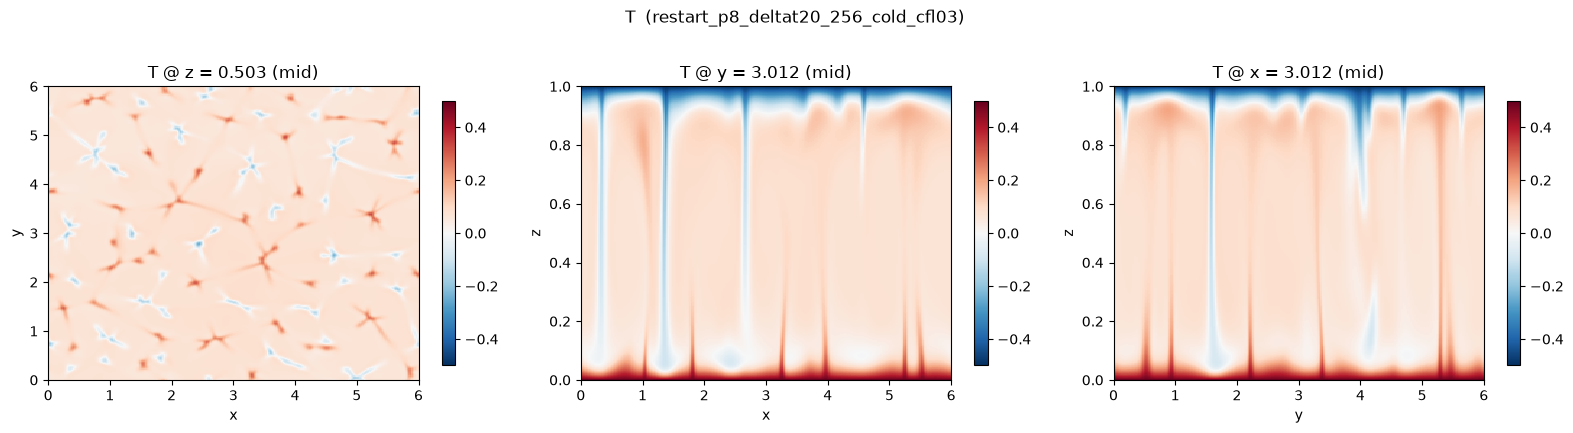

In [9]:
# ---- 3-way mid-plane slices --------------------------------------------------
def plot_slices(name, cmap='RdBu_r', sym=True):
    F = fields[name]
    sl = [
        (F[:, :, k_mid].T, xf, yf, 'x', 'y', f'z = {zc[k_mid]:.3f} (mid)'),   # x-y plane
        (F[:, j_mid, :].T, xf, zf, 'x', 'z', f'y = {yc[j_mid]:.3f} (mid)'),   # x-z plane
        (F[i_mid, :, :].T, yf, zf, 'y', 'z', f'x = {xc[i_mid]:.3f} (mid)'),   # y-z plane
    ]
    if sym:
        vmax = np.abs(F).max(); vmin = -vmax
    else:
        vmin, vmax = F.min(), F.max()
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for ax, (S, cf1, cf2, l1, l2, title) in zip(axes, sl):
        pm = ax.pcolormesh(cf1, cf2, S, cmap=cmap, vmin=vmin, vmax=vmax, shading='flat')
        ax.set_xlabel(l1); ax.set_ylabel(l2); ax.set_title(f'{name} @ {title}')
        fig.colorbar(pm, ax=ax, shrink=0.9)
    fig.suptitle(f'{name}  ({restart_dir.name})', y=1.02)
    fig.tight_layout()
    plt.show()

plot_slices('T')

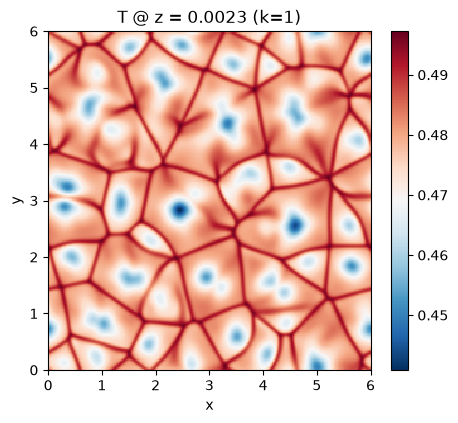

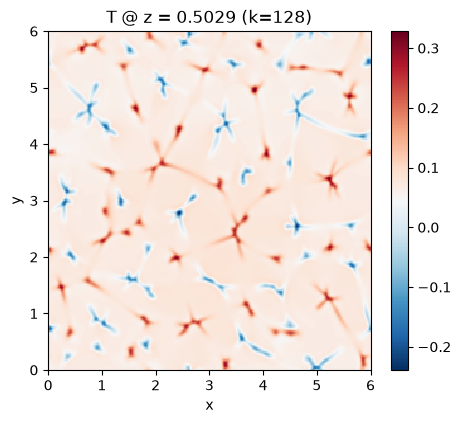

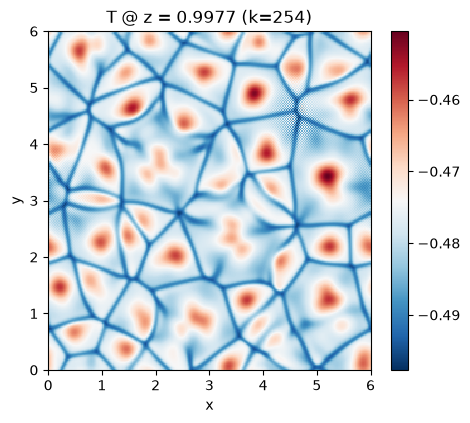

In [10]:
# ---- bonus: near-wall T slices (cold-wall reignition territory, Report/30) ---
for k in [1, int(n3/2), n3 - 2]:                       # first/last interior-ish cells
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    pm = ax.pcolormesh(xf, yf, fields['T'][:, :, k].T, cmap='RdBu_r')
    ax.set_title(f'T @ z = {zc[k]:.4f} (k={k})'); ax.set_xlabel('x'); ax.set_ylabel('y')
    fig.colorbar(pm, ax=ax)
    plt.show()

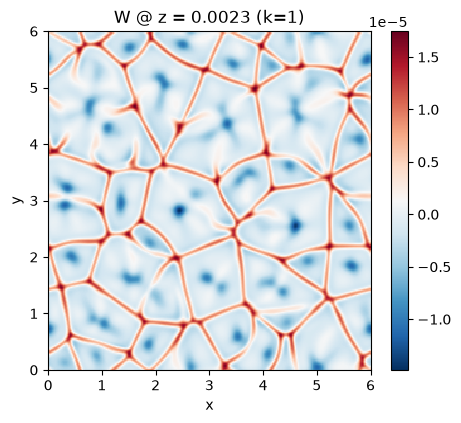

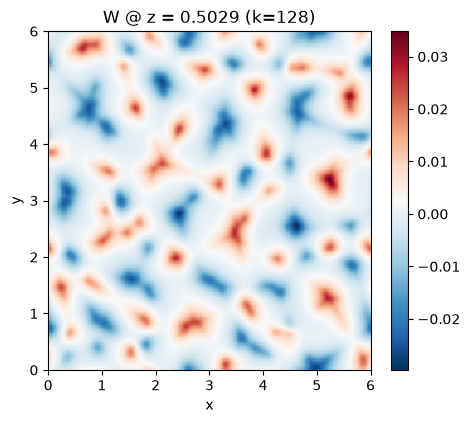

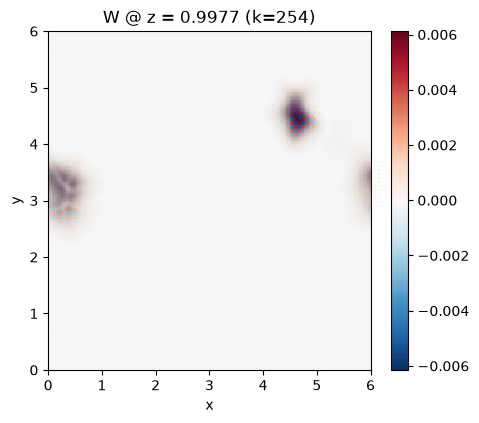

In [11]:
# ---- bonus: near-wall T slices (cold-wall reignition territory, Report/30) ---
for k in [1, int(n3/2), n3 - 2]:                       # first/last interior-ish cells
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    pm = ax.pcolormesh(xf, yf, fields['W'][:, :, k].T, cmap='RdBu_r')
    ax.set_title(f'W @ z = {zc[k]:.4f} (k={k})'); ax.set_xlabel('x'); ax.set_ylabel('y')
    fig.colorbar(pm, ax=ax)
    plt.show()